In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from utils.data_format import numpy4d_to_dataframe
from utils.prep import prepare_2D_lattice_data

import qss

In [2]:
MU_B = 5.788381806e-5  # eV/T
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [3]:
# Band filling values
n_min = 0.1
n_max = 0.99
n_count = 40

# Magnetic field values
Ha_min = 0.0
Ha_max = 10.0
Ha_count = 5

# Beta values
beta_min = 2
beta_max = 3
beta_count = 2

distros = [qss.DistType.FD, qss.DistType.FLB, qss.DistType.NFLB]  # ND
# n  = np.array([0.5, 0.8, 0.9], dtype=np.float64)  # NN
n = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# beta = np.array([0.1, 1.0], dtype=np.float64)  # NB
beta = np.logspace(beta_min, beta_max, beta_count, dtype=np.float64)  # NB
H_a = np.array([0.0], dtype=np.float64)  # NH
# H_a = np.linspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH

In [10]:
opts = qss.CombinedSolverOptions()
opts.solver = qss.SolverType.SimulatedAnnealing

# SA params
opts.sa.T0 = 1.0
opts.sa.alpha = 0.95
opts.sa.max_iters = 5000
opts.sa.min_iters = 50
opts.sa.stall_iters = 100
opts.sa.step_sigma = 0.2
opts.sa.step_decay = 0.99
opts.sa.scale_sigma_by_T = True
opts.sa.bounds = [(-10.0, 10.0)]  # 1D bound for mu
opts.sa.reflect_bounds = True
opts.sa.seed = 12345

x0 = 0.0  # start guess

In [ ]:
# opts.solver = qss.SolverType.Brent

# #Bracketer
# opts.bracketer_type = qss.BracketerType.Expansion
# print(opts.bracketer_opts)
# #Brent
# opts.root.abs_tol = 1e-6
# opts.root.rel_tol = 1e-4
# opts.root.max_iters = 5000

In [11]:
mus = qss.chemical_potential_B(
    distros=distros,
    n_assumed=n,
    beta=beta,
    H_a_T=H_a,
    N=N,
    E=e_k,
    g=2.0,
    muB_eV_per_T=MU_B,
    opts=opts,
    a0=-10.0,
    b0=10.0,
    x0=0.0,
    threads=0,
)

In [12]:
mu_df = numpy4d_to_dataframe(mus, distros=distros, n=n, beta=beta, H_a=H_a)
mu_df

0.100000  0.122821  0.145641  0.168462  0.191282  \
distributions beta   H_a                                                     
FD            100.0  0.0 -1.415453 -1.415453 -1.415453 -1.415453 -1.415453   
              1000.0 0.0 -1.406335 -1.406335 -1.406335 -1.406335 -1.406335   
FLB           100.0  0.0 -1.415453 -1.415453 -1.415453 -1.415453 -1.415453   
              1000.0 0.0 -1.381676 -1.381676 -1.381676 -1.381676 -1.381676   
NFLB          100.0  0.0 -0.848802 -0.848802 -0.848802 -0.848802 -0.848802   
              1000.0 0.0 -0.856262 -0.856262 -0.856262 -0.856262 -0.856262   

                          0.214103  0.236923  0.259744  0.282564  0.305385  \
distributions beta   H_a                                                     
FD            100.0  0.0 -1.415453 -1.415453 -1.415453 -1.415453 -1.415453   
              1000.0 0.0 -1.406335 -1.406335 -1.406335 -1.406335 -1.406335   
FLB           100.0  0.0 -1.415453 -1.415453 -1.415453 -1.415453 -1.415453   
              1000.0 0.0 -1.381676 -1.381676 -1.381676 -1.381676 -1.381676   
NFLB          100.0  0.0 -0.848802 -0.848802 -0.848802 -0.848802 -0.848802   
              1000.0 0.0 -0.856262 -0.856262 -0.856262 -0.856262 -0.856262   

                          ...  0.784615  0.807436  0.830256  0.853077  \
distributions beta   H_a  ...                                           
FD            100.0  0.0  ... -0.995580 -0.965997 -0.933680 -0.894265   
              1000.0 0.0  ... -0.995871 -0.964523 -0.934799 -0.890494   
FLB           100.0  0.0  ... -1.002518 -0.972922 -0.940609 -0.901194   
              1000.0 0.0  ... -0.996566 -0.965216 -0.935478 -0.891192   
NFLB          100.0  0.0  ...  0.068887  0.068887  0.068887  0.068887   
              1000.0 0.0  ...  0.038037  0.038037  0.038037  0.038037   

                          0.875897  0.898718  0.921538  0.944359  0.967179  \
distributions beta   H_a                                                     
FD            100.0  0.0 -0.851355 -0.807961 -0.756890 -0.710382 -0.652173   
              1000.0 0.0 -0.851401 -0.806668 -0.753546 -0.713027 -0.650789   
FLB           100.0  0.0 -0.856957 -0.814892 -0.763828 -0.717312 -0.656460   
              1000.0 0.0 -0.852090 -0.807363 -0.754782 -0.713027 -0.651472   
NFLB          100.0  0.0  0.068887  0.068887  0.068887  0.068887  0.068887   
              1000.0 0.0  0.038037  0.038037  0.038037  0.038037  0.038037   

                          0.990000  
distributions beta   H_a            
FD            100.0  0.0 -0.600016  
              1000.0 0.0 -0.600130  
FLB           100.0  0.0 -0.606956  
              1000.0 0.0 -0.600826  
NFLB          100.0  0.0  0.068887  
              1000.0 0.0  0.038037  

[6 rows x 40 columns]

In [13]:
constant_beta_Ha = mu_df.loc[(("FD", "FLB", "NFLB"), beta[-1], H_a[0]), n]
constant_beta_Ha

,,,0.100000,0.122821,0.145641,0.168462,0.191282,0.214103,0.236923,0.259744,0.282564,0.305385,...,0.784615,0.807436,0.830256,0.853077,0.875897,0.898718,0.921538,0.944359,0.967179,0.990000
distributions,beta,H_a,,,,,,,,,,,,,,,,,,,,,
FD,1000.0,0.0,-1.406335,-1.406335,-1.406335,-1.406335,-1.406335,-1.406335,-1.406335,-1.406335,-1.406335,-1.406335,...,-0.995871,-0.964523,-0.934799,-0.890494,-0.851401,-0.806668,-0.753546,-0.713027,-0.650789,-0.600130
FLB,1000.0,0.0,-1.381676,-1.381676,-1.381676,-1.381676,-1.381676,-1.381676,-1.381676,-1.381676,-1.381676,-1.381676,...,-0.996566,-0.965216,-0.935478,-0.891192,-0.852090,-0.807363,-0.754782,-0.713027,-0.651472,-0.600826
NFLB,1000.0,0.0,-0.856262,-0.856262,-0.856262,-0.856262,-0.856262,-0.856262,-0.856262,-0.856262,-0.856262,-0.856262,...,0.038037,0.038037,0.038037,0.038037,0.038037,0.038037,0.038037,0.038037,0.038037,0.038037


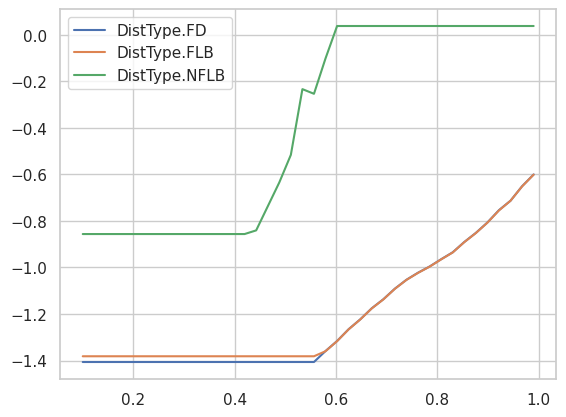

In [14]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots()
data = constant_beta_Ha.to_numpy()
for i, dist in enumerate(distros):
    ax.plot(n, data[i, :], label=dist)

ax.legend()